In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/Mall_Customers.csv


# 1. Import Libraries & Load Dataset

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

dataset = pd.read_csv("/kaggle/input/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/Mall_Customers.csv")

X = dataset
print("Dataset shape:", X.shape)
print("\nFirst 5 observations:")
print(X.iloc[:5, :6].round(2).to_string(index=False))

Dataset shape: (200, 5)

First 5 observations:
 CustomerID Gender  Age  Annual Income (k$)  Spending Score (1-100)
          1   Male   19                  15                      39
          2   Male   21                  15                      81
          3 Female   20                  16                       6
          4 Female   23                  16                      77
          5 Female   31                  17                      40


# Data Quality & EDA

In [3]:
# Drop unnecessary column
X = X.drop(columns=['CustomerID'])

# Missing values
print("Missing values:", X.isna().sum().sum())

# Duplicate observations
print("Duplicate rows:", X.duplicated().sum())

# Descriptive statistics
selected_features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)",
]

print(X.describe().loc[["mean", "std", "min", "max"]].round(2))

Missing values: 0
Duplicate rows: 0
        Age  Annual Income (k$)  Spending Score (1-100)
mean  38.85               60.56                   50.20
std   13.97               26.26                   25.82
min   18.00               15.00                    1.00
max   70.00              137.00                   99.00


# Outlier Detection - IQR Method

In [4]:
selected_features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]
Q1 = X[selected_features].quantile(0.25)
Q3 = X[selected_features].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (X[selected_features] < lower_bound) |
    (X[selected_features] > upper_bound)
).any(axis=1)

print("Outlier observations:", outlier_mask.sum())

Outlier observations: 2


# Feature Scaling

In [5]:
X['Gender'] = X['Gender'].map({'Female': 0, 'Male': 1})

In [6]:
X.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40


In [8]:
scale_cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

In [9]:
# Keep X in original units for cluster profiling and subsampling stability.
# Apply StandardScaler only to numerical features; Gender remains 0/1.
scaler = StandardScaler()
X_scaled = X.copy()
X_scaled[scale_cols] = scaler.fit_transform(X[scale_cols])

In [10]:
display(X_scaled)

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,-1.424569,-1.738999,-0.434801
1,1,-1.281035,-1.738999,1.195704
2,0,-1.352802,-1.700830,-1.715913
3,0,-1.137502,-1.700830,1.040418
4,0,-0.563369,-1.662660,-0.395980
...,...,...,...,...
195,0,-0.276302,2.268791,1.118061
196,0,0.441365,2.497807,-0.861839
197,1,-0.491602,2.497807,0.923953
198,1,-0.491602,2.917671,-1.250054


In [12]:
# The scaled training matrix retains the same feature names and order as X.
X_scaled = X_scaled[X.columns].copy()

# K-Means++ Clustering & Optimal K

In [13]:
results = []
for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    results.append({
        "k": k,
        "Silhouette": round(
            silhouette_score(X_scaled, labels), 3
        ),
        "DBI": round(
            davies_bouldin_score(X_scaled, labels), 3
        ),
        "CH": round(
            calinski_harabasz_score(X_scaled, labels), 1
        )
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

 k  Silhouette   DBI    CH
 2       0.303 1.361  95.2
 3       0.314 1.170  87.2
 4       0.350 1.065 101.5
 5       0.350 1.025  97.3
 6       0.356 1.005  99.7


# Final K-Means++ Model

In [14]:
best_k = int(
    results_df.loc[
        results_df["Silhouette"].idxmax(), "k"
    ]
)

final_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)

cluster_labels = final_model.fit_predict(X_scaled)

print("Optimal K:", best_k)

print("\nCluster sizes:")
print(
    pd.Series(cluster_labels)
    .value_counts()
    .sort_index()
    .to_string()
)

Optimal K: 6

Cluster sizes:
0    45
1    39
2    21
3    34
4    23
5    38


# 2D Cluster Visualization via PCA

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


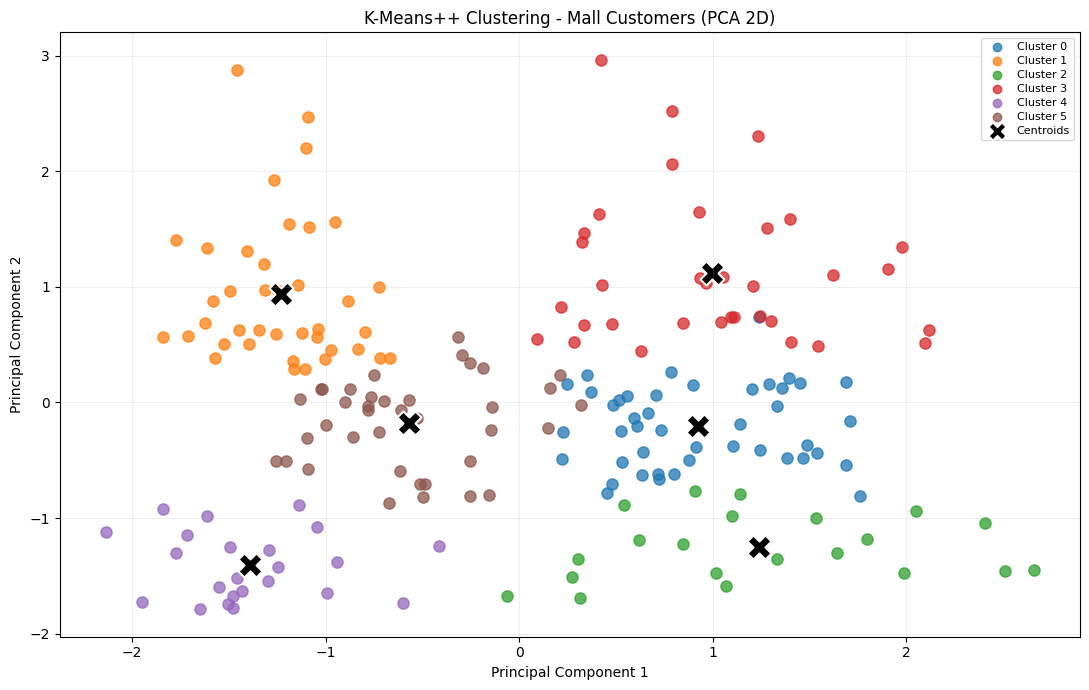

PC1 Explained Variance: 40.95%
PC2 Explained Variance: 30.82%
Total Explained Variance: 71.77%


In [15]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Reduce the scaled data to two dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Project K-Means centroids into PCA space
centroids_pca = pca.transform(
    final_model.cluster_centers_
)

# Create visualization
plt.figure(figsize=(11, 7))

for cluster_id in np.unique(cluster_labels):
    mask = cluster_labels == cluster_id

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        s=65,
        alpha=0.75,
        label=f"Cluster {cluster_id}"
    )

# Visualize cluster centroids
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    c="black",
    marker="X",
    s=300,
    edgecolors="white",
    linewidths=1.5,
    label="Centroids"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means++ Clustering - Mall Customers (PCA 2D)")

plt.legend(fontsize=8, markerscale=0.75, labelspacing=0.35, borderpad=0.4)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Explained variance
print("PC1 Explained Variance:",f"{pca.explained_variance_ratio_[0]:.2%}")

print("PC2 Explained Variance:",f"{pca.explained_variance_ratio_[1]:.2%}")

print("Total Explained Variance:",f"{pca.explained_variance_ratio_.sum():.2%}")

# Silhouette Analysis

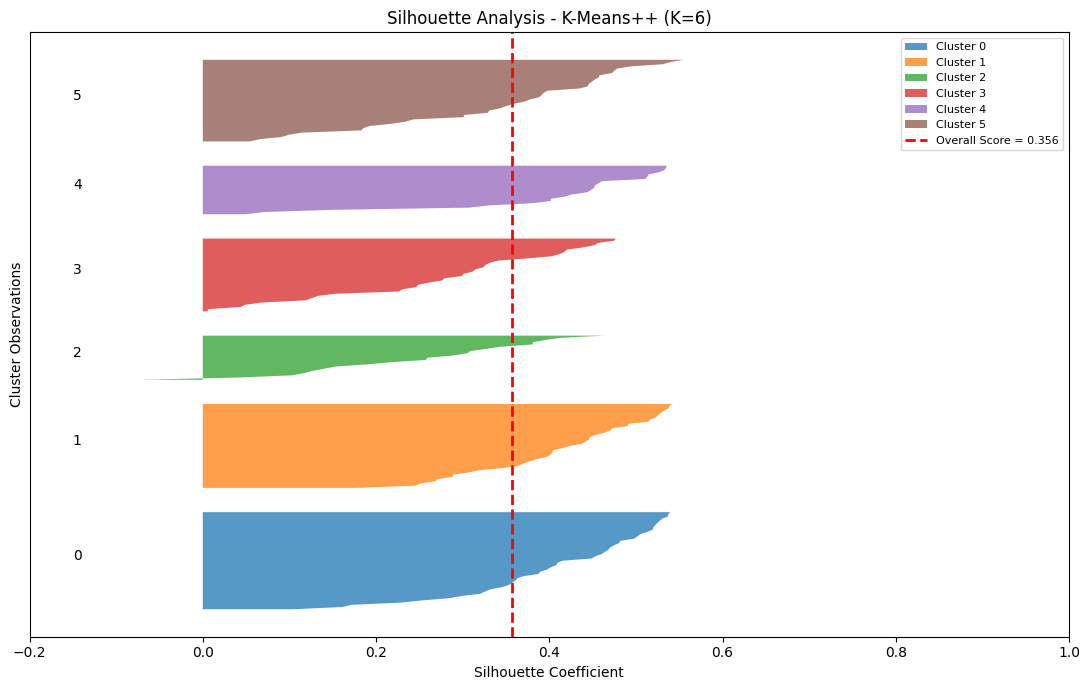

Overall Silhouette Score: 0.356

Cluster-level Summary:
         observations  mean_silhouette  min_silhouette  negative_samples
cluster                                                                 
0                  45            0.409           0.104                 0
1                  39            0.412           0.177                 0
2                  21            0.245          -0.072                 1
3                  34            0.275           0.006                 0
4                  23            0.405           0.050                 0
5                  38            0.342           0.054                 0


In [16]:
from sklearn.metrics import (
    silhouette_samples,
    silhouette_score
)

# Calculate silhouette score for each observation
sample_scores = silhouette_samples(
    X_scaled,
    cluster_labels
)

# Calculate overall silhouette score
overall_score = silhouette_score(
    X_scaled,
    cluster_labels
)

# Create silhouette analysis figure
fig, ax = plt.subplots(figsize=(11, 7))

y_lower = 10

for cluster_id in np.unique(cluster_labels):

    # Select scores belonging to this cluster
    cluster_scores = sample_scores[
        cluster_labels == cluster_id
    ]

    # Sort scores
    cluster_scores.sort()

    cluster_size = len(cluster_scores)
    y_upper = y_lower + cluster_size

    # Plot silhouette distribution
    ax.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        cluster_scores,
        alpha=0.75,
        label=f"Cluster {cluster_id}"
    )

    # Add cluster label
    ax.text(
        -0.15,
        y_lower + 0.5 * cluster_size,
        str(cluster_id)
    )

    y_lower = y_upper + 10

# Overall silhouette score
ax.axvline(
    x=overall_score,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Overall Score = {overall_score:.3f}"
)

ax.set_title(f"Silhouette Analysis - K-Means++ (K={final_model.n_clusters})")
ax.set_xlabel("Silhouette Coefficient")
ax.set_ylabel("Cluster Observations")
ax.set_xlim([-0.2, 1.0])
ax.set_yticks([])
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# Cluster-level summary
silhouette_df = pd.DataFrame({
    "cluster": cluster_labels,
    "silhouette": sample_scores
})

cluster_summary = silhouette_df.groupby("cluster").agg(
    observations=("silhouette", "size"),
    mean_silhouette=("silhouette", "mean"),
    min_silhouette=("silhouette", "min"),
    negative_samples=(
        "silhouette",
        lambda x: (x < 0).sum()
    )
)

print("Overall Silhouette Score:", round(overall_score, 3))
print("\nCluster-level Summary:")
print(cluster_summary.round(3))

# Cluster Profiling

In [17]:
clustered_df = X.copy()

clustered_df["cluster"] = cluster_labels

cluster_profile = (
    clustered_df
    .groupby("cluster")[selected_features]
    .mean()
    .round(2)
)

print(cluster_profile)

           Age  Annual Income (k$)  Spending Score (1-100)
cluster                                                   
0        56.33               54.27                   49.07
1        32.69               86.54                   82.13
2        45.52               26.29                   19.38
3        41.26               88.50                   16.76
4        25.00               25.26                   77.61
5        27.00               56.66                   49.13


In [18]:
# Define meaningful cluster names
cluster_names = {
    0: "Middle-Aged & Moderate Spenders",
    1: "High Income & High Spenders (VIP)",
    2: "Low Income & Low Spenders",
    3: "High Income & Low Spenders (Conservative)",
    4: "Young & High Spenders",
    5: "Standard / Average Customers"
}

# Assign descriptive names to each observation
clustered_df["cluster_name"] = clustered_df["cluster"].map(cluster_names)

# Display cluster distribution
print(
    clustered_df["cluster_name"]
    .value_counts()
    .to_string()
)

cluster_name
Middle-Aged & Moderate Spenders              45
High Income & High Spenders (VIP)            39
Standard / Average Customers                 38
High Income & Low Spenders (Conservative)    34
Young & High Spenders                        23
Low Income & Low Spenders                    21


In [19]:
# Predict cluster for a new customer using the SAME preprocessing as training
new_customer = pd.DataFrame([{
    "Gender": 1,  # Female=0, Male=1
    "Age": 28,
    "Annual Income (k$)": 12,
    "Spending Score (1-100)": 60
}])[X.columns]

new_customer_scaled = new_customer.copy()
new_customer_scaled[scale_cols] = scaler.transform(new_customer[scale_cols])

predicted_cluster = int(final_model.predict(new_customer_scaled)[0])
print("Cluster:", predicted_cluster)
print("Segment:", cluster_names[predicted_cluster])

Cluster: 4
Segment: Young & High Spenders


# Different Clustering Algorithms

In [20]:
from sklearn.cluster import (
    AgglomerativeClustering,
    DBSCAN,
    SpectralClustering
)
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Use the same number of clusters for comparable algorithms
k = final_model.n_clusters

models = {
    "K-Means++": final_model,

    "Agglomerative": AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    ),

    "Gaussian Mixture": GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=42,
        n_init=10
    ),

    "DBSCAN": DBSCAN(
        eps=2.2,
        min_samples=5
    ),

    "Spectral": SpectralClustering(
        n_clusters=k,
        affinity="nearest_neighbors",
        n_neighbors=10,
        assign_labels="kmeans",
        random_state=42
    )
}

cluster_predictions = {}
evaluation_results = []

for name, model in models.items():

    # Reuse previously fitted K-Means predictions
    if name == "K-Means++":
        labels = cluster_labels.copy()
    else:
        labels = model.fit_predict(X_scaled)

    cluster_predictions[name] = labels

    # Exclude DBSCAN noise observations
    valid_mask = labels != -1
    valid_labels = labels[valid_mask]

    n_clusters = len(np.unique(valid_labels))
    n_noise = np.sum(~valid_mask)
    coverage = valid_mask.mean()

    silhouette = np.nan
    dbi = np.nan
    ch = np.nan

    # Metrics require at least two valid clusters
    if 2 <= n_clusters < valid_mask.sum():

        score_X = X_scaled[valid_mask]

        silhouette = silhouette_score(
            score_X, valid_labels
        )

        dbi = davies_bouldin_score(
            score_X, valid_labels
        )

        ch = calinski_harabasz_score(
            score_X, valid_labels
        )

    evaluation_results.append({
        "Algorithm": name,
        "Clusters": n_clusters,
        "Noise": n_noise,
        "Coverage": coverage,
        "Silhouette": silhouette,
        "DBI": dbi,
        "CH": ch
    })

comparison_df = pd.DataFrame(evaluation_results)

print(comparison_df.round(3).to_string(index=False))

       Algorithm  Clusters  Noise  Coverage  Silhouette   DBI     CH
       K-Means++         6      0       1.0       0.356 1.005 99.655
   Agglomerative         6      0       1.0       0.350 1.009 95.258
Gaussian Mixture         6      0       1.0       0.041 1.644 21.869
          DBSCAN         1      0       1.0         NaN   NaN    NaN
        Spectral         6      0       1.0       0.249 1.387 70.431


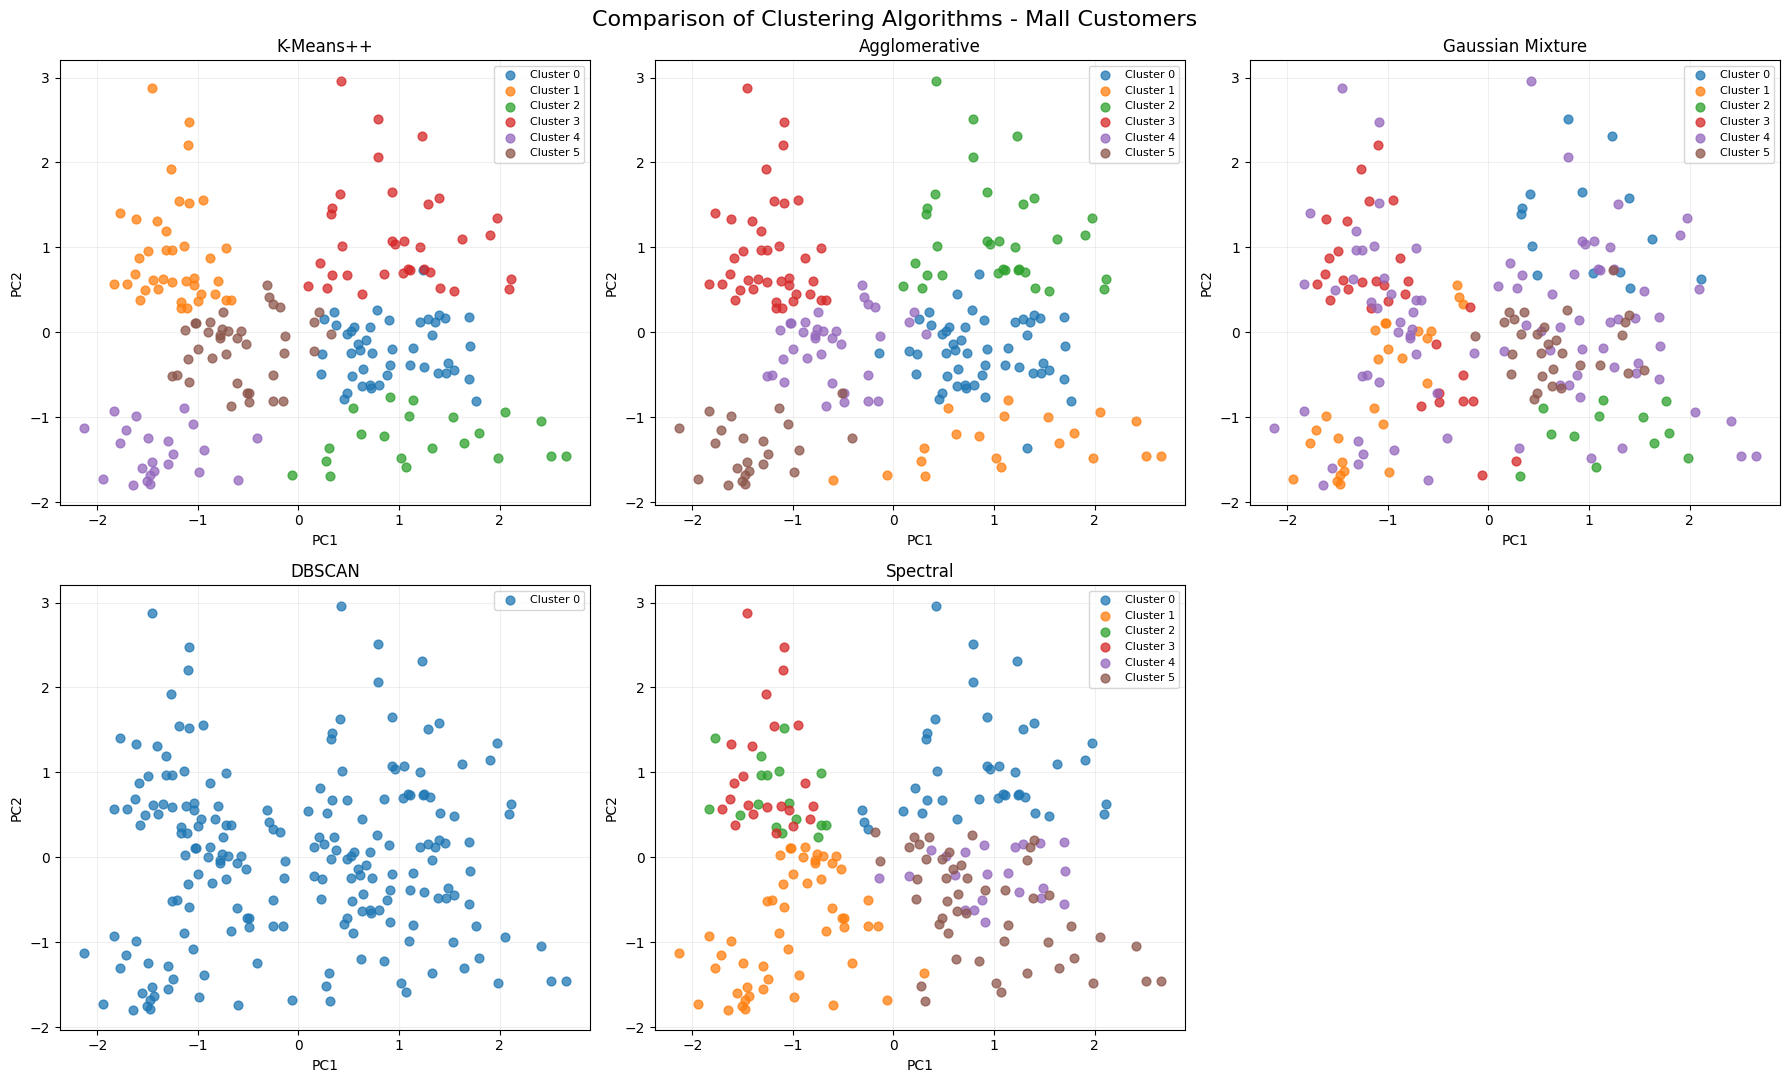

In [21]:
# Use the same PCA projection for every model
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 11)
)

axes = axes.flatten()

for ax, (name, labels) in zip(
    axes, cluster_predictions.items()
):

    unique_labels = np.unique(labels)

    for cluster_id in unique_labels:

        mask = labels == cluster_id

        # Draw noise observations separately
        if cluster_id == -1:
            ax.scatter(
                X_pca[mask, 0],
                X_pca[mask, 1],
                c="gray",
                marker="x",
                s=45,
                label="Noise"
            )
        else:
            ax.scatter(
                X_pca[mask, 0],
                X_pca[mask, 1],
                s=40,
                alpha=0.75,
                label=f"Cluster {cluster_id}"
            )

    ax.set_title(name)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

# Hide unused subplot
for ax in axes[len(cluster_predictions):]:
    ax.axis("off")

plt.suptitle(
    "Comparison of Clustering Algorithms - Mall Customers",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [22]:
# Rank models by Silhouette Score
ranking_df = (
    comparison_df
    .sort_values(
        by="Silhouette",
        ascending=False,
        na_position="last"
    )
    .reset_index(drop=True)
)

print(
    ranking_df[
        [
            "Algorithm",
            "Clusters",
            "Noise",
            "Coverage",
            "Silhouette",
            "DBI",
            "CH"
        ]
    ].round(3).to_string(index=False)
)

       Algorithm  Clusters  Noise  Coverage  Silhouette   DBI     CH
       K-Means++         6      0       1.0       0.356 1.005 99.655
   Agglomerative         6      0       1.0       0.350 1.009 95.258
        Spectral         6      0       1.0       0.249 1.387 70.431
Gaussian Mixture         6      0       1.0       0.041 1.644 21.869
          DBSCAN         1      0       1.0         NaN   NaN    NaN


# K-Means++ Hyperparameter Tuning

In [23]:
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
import numpy as np
import pandas as pd

# Hyperparameter grid
k_values = range(2, 11)
n_init_values = [10, 20, 30, 50]
max_iter_values = [300, 500, 1000]
tol_values = [1e-3, 1e-4]

kmeans_results = []

for k in k_values:
    for n_init in n_init_values:
        for max_iter in max_iter_values:
            for tol in tol_values:

                model = KMeans(
                    n_clusters=k,
                    init="k-means++",
                    n_init=n_init,
                    max_iter=max_iter,
                    tol=tol,
                    random_state=42
                )

                labels = model.fit_predict(X_scaled)

                n_clusters = len(np.unique(labels))

                # Evaluate clustering performance
                silhouette = silhouette_score(
                    X_scaled, labels
                )

                dbi = davies_bouldin_score(
                    X_scaled, labels
                )

                ch = calinski_harabasz_score(
                    X_scaled, labels
                )

                kmeans_results.append({
                    "k": k,
                    "n_init": n_init,
                    "max_iter": max_iter,
                    "tol": tol,
                    "n_clusters": n_clusters,
                    "inertia": model.inertia_,
                    "silhouette": silhouette,
                    "DBI": dbi,
                    "CH": ch,
                    "iterations": model.n_iter_
                })

kmeans_tuning_df = pd.DataFrame(kmeans_results)

# Show top configurations by Silhouette Score
valid_results = kmeans_tuning_df[
    kmeans_tuning_df["n_clusters"] >= 2
]

print("Top K-Means++ configurations:")

print(
    valid_results.sort_values(
        ["silhouette", "DBI"],
        ascending=[False, True]
    ).head(10).round(4).to_string(index=False)
)

print(
    "\nNumber of evaluated configurations:",
    len(kmeans_tuning_df)
)

# Select best configuration
best_config = valid_results.sort_values(
    ["silhouette", "DBI"],
    ascending=[False, True]
).iloc[0]

print("\nBest K-Means++ Configuration:")
print(best_config.to_string())

# Train final tuned model
best_kmeans = KMeans(
    n_clusters=int(best_config["k"]),
    init="k-means++",
    n_init=int(best_config["n_init"]),
    max_iter=int(best_config["max_iter"]),
    tol=float(best_config["tol"]),
    random_state=42
)

best_labels = best_kmeans.fit_predict(X_scaled)

print("\nFinal Model Silhouette Score:",round(silhouette_score(X_scaled, best_labels), 4))

Top K-Means++ configurations:
 k  n_init  max_iter    tol  n_clusters  inertia  silhouette    DBI      CH  iterations
 6      10       300 0.0010           6 181.9514      0.3565 1.0051 99.6549           6
 6      10       300 0.0001           6 181.9514      0.3565 1.0051 99.6549           6
 6      10       500 0.0010           6 181.9514      0.3565 1.0051 99.6549           6
 6      10       500 0.0001           6 181.9514      0.3565 1.0051 99.6549           6
 6      10      1000 0.0010           6 181.9514      0.3565 1.0051 99.6549           6
 6      10      1000 0.0001           6 181.9514      0.3565 1.0051 99.6549           6
 6      20       300 0.0010           6 181.9514      0.3565 1.0051 99.6549           6
 6      20       300 0.0001           6 181.9514      0.3565 1.0051 99.6549           6
 6      20       500 0.0010           6 181.9514      0.3565 1.0051 99.6549           6
 6      20       500 0.0001           6 181.9514      0.3565 1.0051 99.6549           6

N

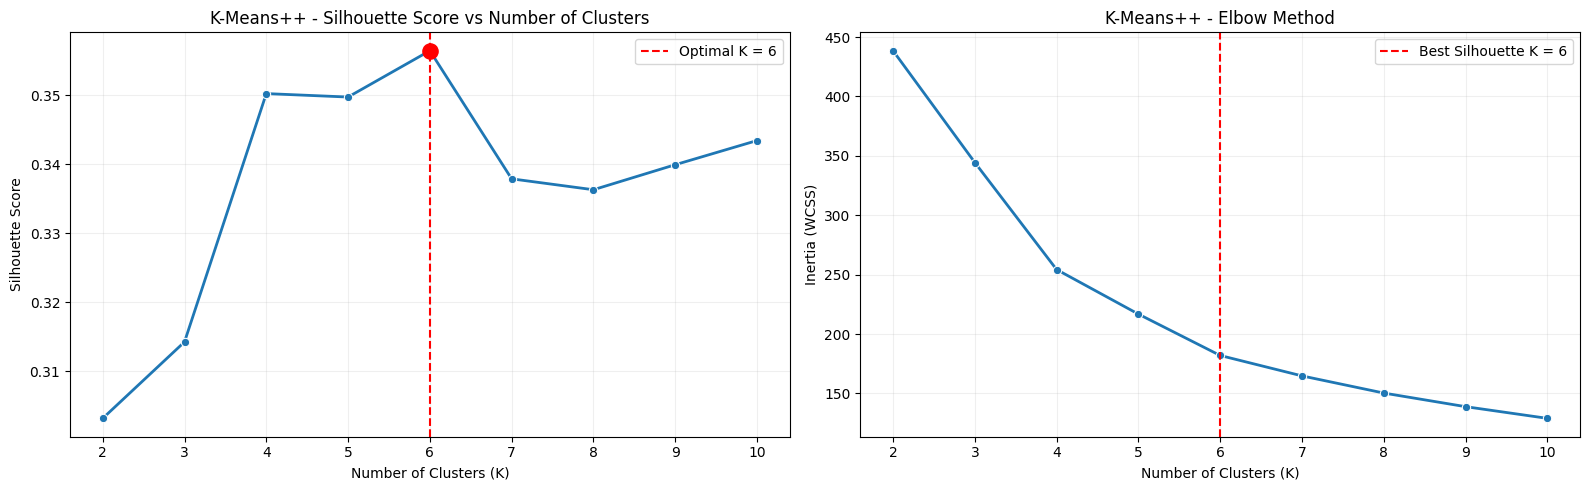

In [24]:
import seaborn as sns

# Aggregate results for each k
# Select the configuration with the lowest inertia for each k
plot_df = (
    kmeans_tuning_df
    .sort_values("inertia")
    .drop_duplicates(subset=["k"])
    .sort_values("k")
    .reset_index(drop=True)
)

# Find optimal k based on Silhouette Score
best_idx = plot_df["silhouette"].idxmax()
best_k = int(plot_df.loc[best_idx, "k"])
best_silhouette = plot_df.loc[best_idx, "silhouette"]

# Create visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Silhouette Score vs Number of Clusters
sns.lineplot(
    data=plot_df,
    x="k",
    y="silhouette",
    marker="o",
    linewidth=2,
    ax=axes[0]
)

axes[0].axvline(
    x=best_k,
    color="red",
    linestyle="--",
    label=f"Optimal K = {best_k}"
)

axes[0].scatter(
    best_k,
    best_silhouette,
    color="red",
    s=120,
    zorder=5
)

axes[0].set_title(
    "K-Means++ - Silhouette Score vs Number of Clusters"
)
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Silhouette Score")
axes[0].set_xticks(plot_df["k"])
axes[0].legend()
axes[0].grid(alpha=0.2)


# 2. Elbow Method - Inertia vs Number of Clusters
sns.lineplot(
    data=plot_df,
    x="k",
    y="inertia",
    marker="o",
    linewidth=2,
    ax=axes[1]
)

axes[1].axvline(
    x=best_k,
    color="red",
    linestyle="--",
    label=f"Best Silhouette K = {best_k}"
)

axes[1].set_title(
    "K-Means++ - Elbow Method"
)
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Inertia (WCSS)")
axes[1].set_xticks(plot_df["k"])
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

# ARI & NMI Comparision

In [25]:
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

# Compare only models that assigned every observation
model_names = [
    "K-Means++",
    "Agglomerative",
    "Gaussian Mixture",
    "Spectral"
]

ari_matrix = pd.DataFrame(
    index=model_names,
    columns=model_names,
    dtype=float
)

nmi_matrix = pd.DataFrame(
    index=model_names,
    columns=model_names,
    dtype=float
)

# Pairwise comparison
for model_a in model_names:
    for model_b in model_names:

        labels_a = cluster_predictions[model_a]
        labels_b = cluster_predictions[model_b]

        ari_matrix.loc[model_a, model_b] = (
            adjusted_rand_score(labels_a, labels_b)
        )

        nmi_matrix.loc[model_a, model_b] = (
            normalized_mutual_info_score(
                labels_a,
                labels_b
            )
        )

print("Adjusted Rand Index (ARI):")
print(ari_matrix.round(3))

print("\nNormalized Mutual Information (NMI):")
print(nmi_matrix.round(3))

Adjusted Rand Index (ARI):
                  K-Means++  Agglomerative  Gaussian Mixture  Spectral
K-Means++             1.000          0.892             0.179     0.514
Agglomerative         0.892          1.000             0.181     0.509
Gaussian Mixture      0.179          0.181             1.000     0.237
Spectral              0.514          0.509             0.237     1.000

Normalized Mutual Information (NMI):
                  K-Means++  Agglomerative  Gaussian Mixture  Spectral
K-Means++             1.000          0.896             0.425     0.674
Agglomerative         0.896          1.000             0.418     0.686
Gaussian Mixture      0.425          0.418             1.000     0.497
Spectral              0.674          0.686             0.497     1.000


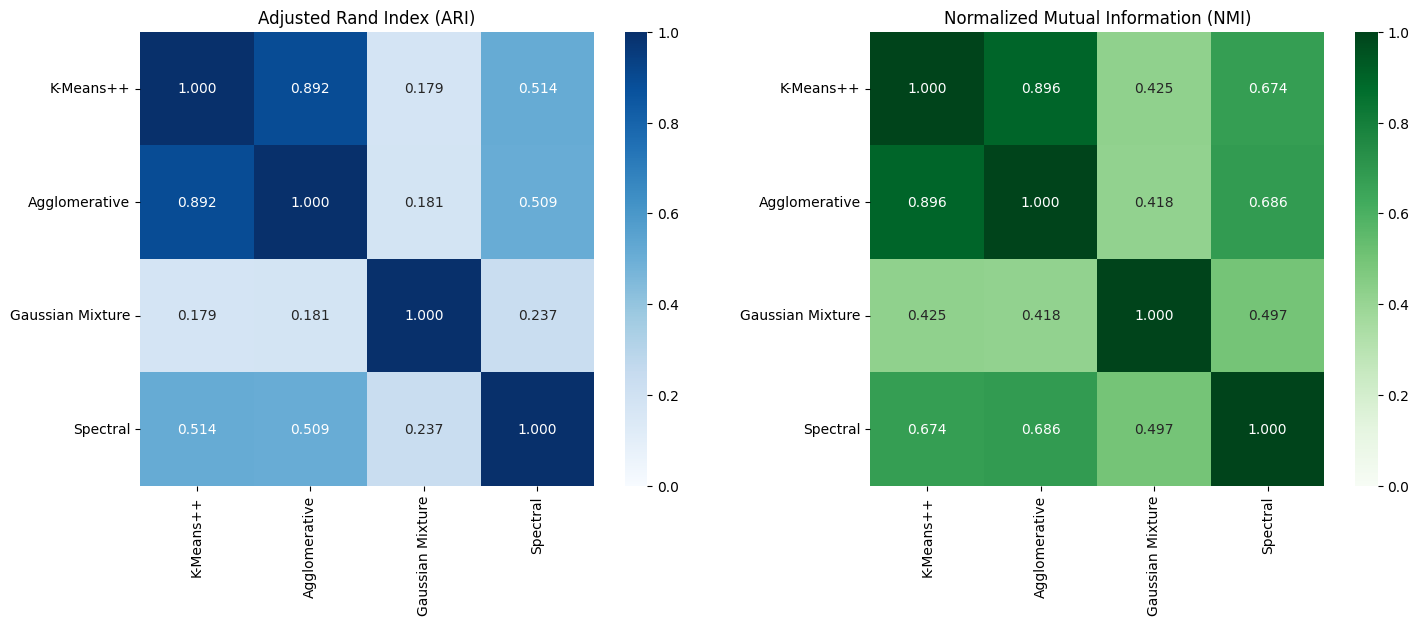

In [26]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6)
)

sns.heatmap(
    ari_matrix,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    square=True,
    ax=axes[0]
)

axes[0].set_title(
    "Adjusted Rand Index (ARI)"
)

sns.heatmap(
    nmi_matrix,
    annot=True,
    fmt=".3f",
    cmap="Greens",
    vmin=0,
    vmax=1,
    square=True,
    ax=axes[1]
)

axes[1].set_title(
    "Normalized Mutual Information (NMI)"
)

plt.tight_layout()
plt.show()

In [27]:
from itertools import combinations

pairwise_results = []

for model_a, model_b in combinations(model_names, 2):

    pairwise_results.append({
        "Model A": model_a,
        "Model B": model_b,
        "ARI": adjusted_rand_score(
            cluster_predictions[model_a],
            cluster_predictions[model_b]
        ),
        "NMI": normalized_mutual_info_score(
            cluster_predictions[model_a],
            cluster_predictions[model_b]
        )
    })

pairwise_df = pd.DataFrame(pairwise_results)

pairwise_df = pairwise_df.sort_values(
    "ARI",
    ascending=False
).reset_index(drop=True)

print(pairwise_df.round(3).to_string(index=False))

         Model A          Model B   ARI   NMI
       K-Means++    Agglomerative 0.892 0.896
       K-Means++         Spectral 0.514 0.674
   Agglomerative         Spectral 0.509 0.686
Gaussian Mixture         Spectral 0.237 0.497
   Agglomerative Gaussian Mixture 0.181 0.418
       K-Means++ Gaussian Mixture 0.179 0.425


# Cluster Stability Analysis

In [29]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from collections import Counter
from itertools import combinations

# Preserve the original experiment: 100 different random initializations.
random_seeds = range(100)
predictions = []

for seed in random_seeds:
    model = KMeans(
        n_clusters=final_model.n_clusters,
        init="k-means++",
        random_state=seed,
        n_init=20
    )
    labels = model.fit_predict(X_scaled)
    predictions.append(labels)

# Compute EXACT pairwise ARI statistics efficiently.
# Many runs yield the same partition, perhaps with permuted cluster IDs.
# Count identical partitions once, then weight their pairwise ARI scores.
def canonical_partition(labels):
    label_map = {}
    return tuple(label_map.setdefault(int(value), len(label_map)) for value in labels)

partition_counts = Counter(canonical_partition(labels) for labels in predictions)
unique_partitions = list(partition_counts.items())
n_comparisons = len(predictions) * (len(predictions) - 1) // 2

weighted_sum = 0.0
weighted_sum_sq = 0.0
minimum_ari = 1.0
maximum_ari = -1.0

for _, count in unique_partitions:
    # Each pair of identical partitions has ARI = 1, even if IDs are permuted.
    weight = count * (count - 1) // 2
    weighted_sum += weight
    weighted_sum_sq += weight
    if weight:
        minimum_ari = min(minimum_ari, 1.0)
        maximum_ari = max(maximum_ari, 1.0)

for (partition_a, count_a), (partition_b, count_b) in combinations(unique_partitions, 2):
    score = adjusted_rand_score(partition_a, partition_b)
    weight = count_a * count_b
    weighted_sum += weight * score
    weighted_sum_sq += weight * score**2
    minimum_ari = min(minimum_ari, score)
    maximum_ari = max(maximum_ari, score)

mean_ari = weighted_sum / n_comparisons
std_ari = np.sqrt(max(0.0, weighted_sum_sq / n_comparisons - mean_ari**2))

print("Number of comparisons:", n_comparisons)
print("Mean ARI:", round(mean_ari, 4))
print("Std ARI:", round(std_ari, 4))
print("Min ARI:", round(minimum_ari, 4))
print("Max ARI:", round(maximum_ari, 4))

Number of comparisons: 4950
Mean ARI: 1.0
Std ARI: 0.0
Min ARI: 1.0
Max ARI: 1.0


# Data Perturbation Stability Analysis

Mean ARI: 0.9851
Std ARI: 0.0236
Min ARI: 0.8804
Max ARI: 1.0
5th percentile: 0.9372


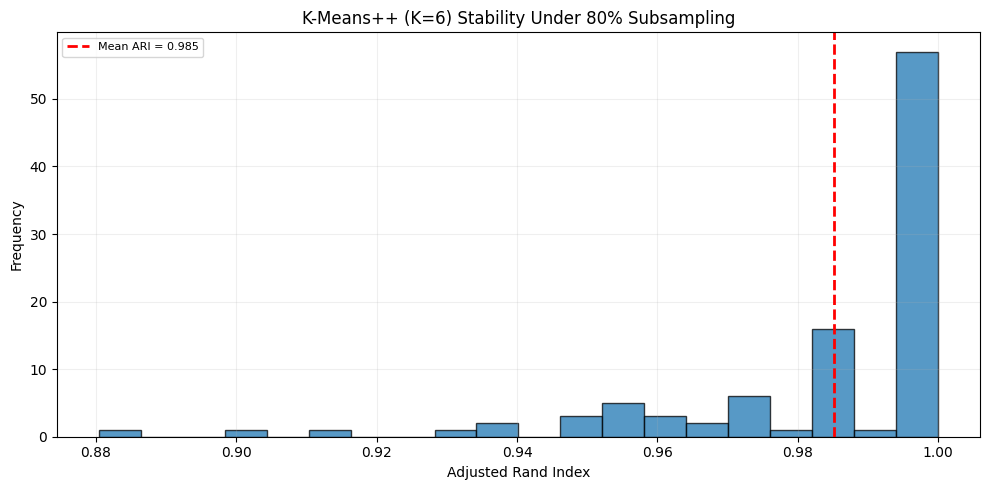

In [30]:
# Experiment settings (keep the original 80% perturbation design)
n_iterations = 100
train_fraction = 0.80

rng = np.random.default_rng(42)
n_samples = len(X)

# Reference assignments from the full-data 6-cluster model
reference_labels = final_model.labels_
stability_results = []

for iteration in range(n_iterations):

    # Randomly select 80% of customers without replacement
    sample_indices = rng.choice(
        n_samples,
        size=int(n_samples * train_fraction),
        replace=False
    )

    # IMPORTANT: refit scaling only on numerical features of the subset.
    # Do not scale Gender; this reproduces the original training procedure.
    X_subset = X.iloc[sample_indices].copy()
    subset_scaler = StandardScaler()
    X_subset_scaled = X_subset.copy()
    X_subset_scaled[scale_cols] = subset_scaler.fit_transform(
        X_subset[scale_cols]
    )

    # Compare models with the same k and optimization settings.
    subset_model = KMeans(
        n_clusters=final_model.n_clusters,
        init="k-means++",
        random_state=42,
        n_init=final_model.n_init,
        max_iter=final_model.max_iter,
        tol=final_model.tol
    )
    subset_labels = subset_model.fit_predict(X_subset_scaled)

    # Both labelings refer to exactly the same sampled customers.
    reference_subset_labels = reference_labels[sample_indices]
    ari = adjusted_rand_score(reference_subset_labels, subset_labels)
    stability_results.append(ari)

stability_results = np.array(stability_results)
print("Mean ARI:", round(stability_results.mean(), 4))
print("Std ARI:", round(stability_results.std(), 4))
print("Min ARI:", round(stability_results.min(), 4))
print("Max ARI:", round(stability_results.max(), 4))
print("5th percentile:", round(np.percentile(stability_results, 5), 4))

# Plot stability distribution
plt.figure(figsize=(10, 5))
plt.hist(stability_results, bins=20, edgecolor="black", alpha=0.75)
plt.axvline(
    stability_results.mean(), color="red", linestyle="--", linewidth=2,
    label=f"Mean ARI = {stability_results.mean():.3f}"
)
plt.xlabel("Adjusted Rand Index")
plt.ylabel("Frequency")
plt.title(f"K-Means++ (K={final_model.n_clusters}) Stability Under 80% Subsampling")
plt.legend(fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Cluster Profiling

In [31]:
# Create a copy of the original dataset
clustered_df = X.copy()

# Add K-Means cluster assignments
clustered_df["Cluster"] = cluster_labels

# Cluster sizes
cluster_sizes = (
    clustered_df["Cluster"]
    .value_counts()
    .sort_index()
)

print("Cluster Sizes:")
print(cluster_sizes)

# Descriptive statistics for each cluster
cluster_stats = clustered_df.groupby("Cluster").agg(
    ["mean", "median", "std", "min", "max"]
)

# Display mean values for all features
cluster_means = (
    clustered_df
    .groupby("Cluster")
    .mean()
)

print("\nCluster Feature Means:")
print(cluster_means.round(3).to_string())

Cluster Sizes:
Cluster
0    45
1    39
2    21
3    34
4    23
5    38
Name: count, dtype: int64

Cluster Feature Means:
         Gender     Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                            
0         0.422  56.333              54.267                  49.067
1         0.462  32.692              86.538                  82.128
2         0.381  45.524              26.286                  19.381
3         0.588  41.265              88.500                  16.765
4         0.435  25.000              25.261                  77.609
5         0.342  27.000              56.658                  49.132


# Standardized Cluster Profile Heatmap

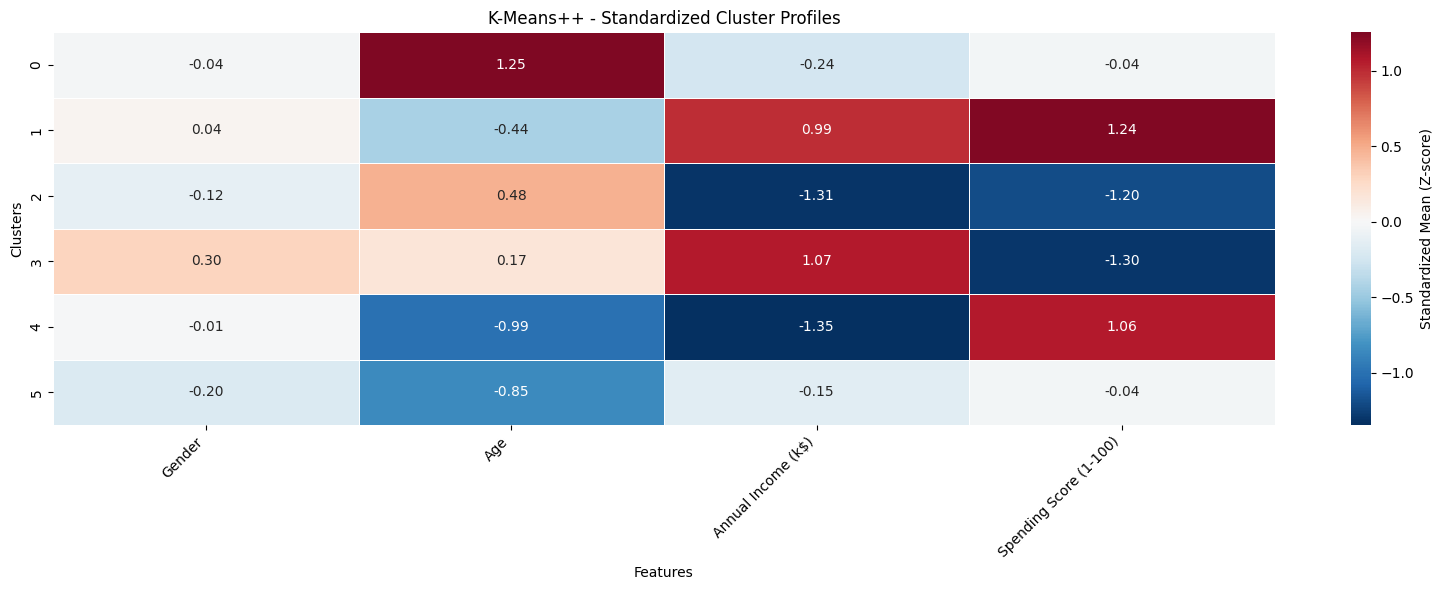

In [32]:
# Standardize cluster-level feature means
cluster_profile_scaled = (
    (cluster_means - X.mean()) /
    X.std(ddof=0)
)

plt.figure(figsize=(16, 6))

sns.heatmap(
    cluster_profile_scaled,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Standardized Mean (Z-score)"}
)

plt.title("K-Means++ - Standardized Cluster Profiles")
plt.xlabel("Features")
plt.ylabel("Clusters")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Feature Distribution - Boxplots

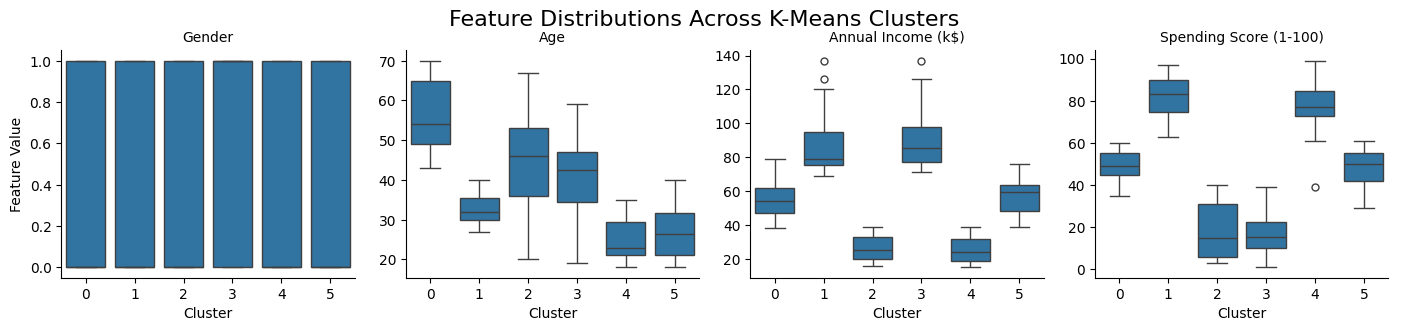

In [33]:
# Convert dataset to long format
plot_df = clustered_df.melt(
    id_vars="Cluster",
    var_name="Feature",
    value_name="Value"
)

# Create separate boxplots for every feature
g = sns.catplot(
    data=plot_df,
    x="Cluster",
    y="Value",
    col="Feature",
    col_wrap=4,
    kind="box",
    sharey=False,
    height=3.2,
    aspect=1.1
)

g.set_titles("{col_name}")
g.set_axis_labels("Cluster", "Feature Value")

g.figure.suptitle(
    "Feature Distributions Across K-Means Clusters",
    fontsize=16,
    y=1.02
)

plt.show()

In [34]:
# Assign descriptive cluster names
clustered_df["Cluster_Name"] = (
    clustered_df["Cluster"].map(cluster_names)
)

# Display cluster distribution
cluster_distribution = (
    clustered_df["Cluster_Name"]
    .value_counts()
    .rename_axis("Cluster Name")
    .reset_index(name="Observations")
)

cluster_distribution["Percentage"] = (
    cluster_distribution["Observations"]
    / len(clustered_df) * 100
).round(2)

print(cluster_distribution.to_string(index=False))

                             Cluster Name  Observations  Percentage
          Middle-Aged & Moderate Spenders            45        22.5
        High Income & High Spenders (VIP)            39        19.5
             Standard / Average Customers            38        19.0
High Income & Low Spenders (Conservative)            34        17.0
                    Young & High Spenders            23        11.5
                Low Income & Low Spenders            21        10.5


# Model Pipeline

In [35]:
import joblib
import sklearn
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# The existing model was fitted with unscaled Gender + scaled numerical features.
# Recreate EXACTLY that feature order, with the scaler inside the pipeline.
preprocessor = ColumnTransformer(
    transformers=[
        ("gender", "passthrough", ["Gender"]),
        ("numeric", StandardScaler(), scale_cols)
    ],
    remainder="drop",
    verbose_feature_names_out=False
).set_output(transform="pandas")
preprocessor.fit(X)

# Verify that pipeline preprocessing matches the matrix used to train K-Means++.
reconstructed_X = preprocessor.transform(X)
assert reconstructed_X.columns.tolist() == X_scaled.columns.tolist()
np.testing.assert_allclose(
    reconstructed_X.to_numpy(), X_scaled.to_numpy(), rtol=1e-10, atol=1e-10
)

clustering_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("kmeans", final_model)
])

# Verify all original training assignments before saving.
np.testing.assert_array_equal(clustering_pipeline.predict(X), cluster_labels)

model_artifact = {
    "pipeline": clustering_pipeline,
    "feature_names": X.columns.tolist(),
    "cluster_names": cluster_names,
    "n_clusters": final_model.n_clusters,
    "sklearn_version": sklearn.__version__
}

# Same notebook works in Kaggle and local Jupyter.
model_path = Path("/kaggle/working/customer_mall_pipeline.joblib") \
    if Path("/kaggle/working").is_dir() else Path("customer_mall_pipeline.joblib")
joblib.dump(model_artifact, model_path)

print("Model saved successfully!", model_path)
print("Clusters:", model_artifact["n_clusters"])
print("Features:", len(model_artifact["feature_names"]))

Model saved successfully! /kaggle/working/customer_mall_pipeline.joblib
Clusters: 6
Features: 4


# Model Load

In [36]:
# Load saved clustering artifact
loaded_artifact = joblib.load(model_path)
loaded_pipeline = loaded_artifact["pipeline"]
feature_names = loaded_artifact["feature_names"]
loaded_cluster_names = loaded_artifact["cluster_names"]

print("Model loaded successfully!")
print("Number of clusters:", loaded_pipeline.named_steps["kmeans"].n_clusters)
print("Required features:", feature_names)

# Smoke test: reloaded pipeline must reproduce training assignments.
np.testing.assert_array_equal(loaded_pipeline.predict(X), cluster_labels)
print("Reloaded model reproduces training assignments.")

Model loaded successfully!
Number of clusters: 6
Required features: ['Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
Reloaded model reproduces training assignments.


# Prediction for new observation

Predicted Cluster: 1
Customer Segment: High Income & High Spenders (VIP)

Distance to Cluster Centroids:


,Cluster,Cluster Name,Distance
0,1,High Income & High Spenders (VIP),0.7813
1,5,Standard / Average Customers,1.2539
2,4,Young & High Spenders,2.1652
3,3,High Income & Low Spenders (Conservative),2.3725
4,0,Middle-Aged & Moderate Spenders,2.4368
5,2,Low Income & Low Spenders,3.1292


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


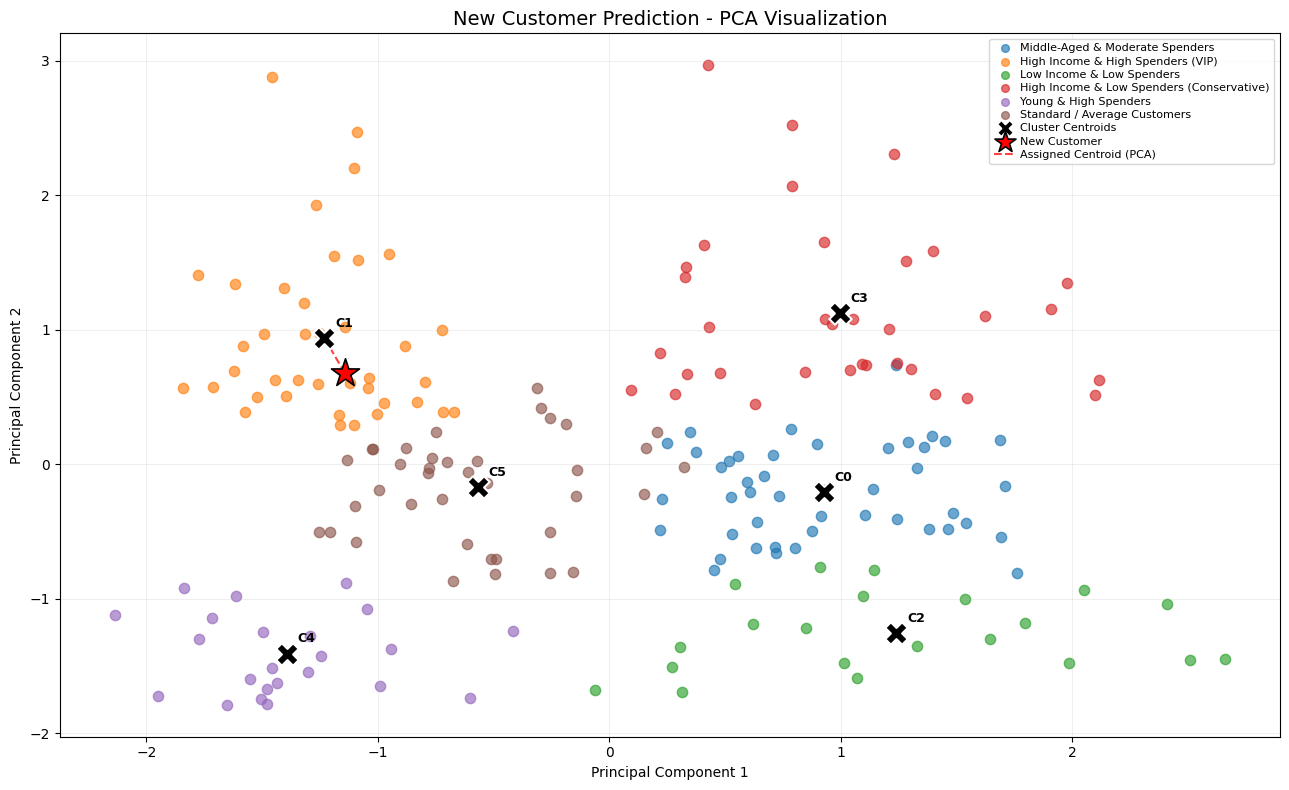

In [52]:
# New customer (same four raw input features used during training)
new_customer_prediction_data = pd.DataFrame([{
    "Gender": 0,  # Female=0, Male=1
    "Age": 28,
    "Annual Income (k$)": 80,
    "Spending Score (1-100)": 70
}])[feature_names]

# No manual scaling needed: the saved pipeline performs it consistently.
predicted_cluster = int(
    loaded_pipeline.predict(new_customer_prediction_data)[0]
)

predicted_name = loaded_cluster_names[predicted_cluster]

print("Predicted Cluster:", predicted_cluster)
print("Customer Segment:", predicted_name)


# Extract fitted preprocessing and K-Means++ components
loaded_preprocessor = loaded_pipeline.named_steps["preprocessor"]
loaded_kmeans = loaded_pipeline.named_steps["kmeans"]

# Transform the new customer using the fitted preprocessor
new_customer_transformed = loaded_preprocessor.transform(
    new_customer_prediction_data
)


# Inspect centroid distances (not calibrated probabilities)
centroid_distances = loaded_kmeans.transform(
    new_customer_transformed
)[0]

distance_df = pd.DataFrame({
    "Cluster": range(len(centroid_distances)),
    "Cluster Name": [
        loaded_cluster_names[i]
        for i in range(len(centroid_distances))
    ],
    "Distance": centroid_distances
}).sort_values("Distance").reset_index(drop=True)

print("\nDistance to Cluster Centroids:")
display(distance_df.round(4))


# Project the new customer into the SAME fitted PCA space
new_customer_pca = pca.transform(
    new_customer_transformed
)

# Project K-Means++ centroids into the SAME PCA space
centroids_pca = pca.transform(
    loaded_kmeans.cluster_centers_
)


# PCA Visualization
plt.figure(figsize=(13, 8))

# Plot existing customer clusters
for cluster_id in np.unique(cluster_labels):

    mask = cluster_labels == cluster_id

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        s=55,
        alpha=0.65,
        label=loaded_cluster_names[int(cluster_id)]
    )


# Plot cluster centroids
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    c="black",
    marker="X",
    s=260,
    edgecolors="white",
    linewidths=1.5,
    label="Cluster Centroids",
    zorder=8
)

# Add centroid labels (C0, C1, ..., C5)
for cluster_id, (x, y) in enumerate(centroids_pca):

    plt.annotate(
        f"C{cluster_id}",
        xy=(x, y),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
        color="black",
        zorder=9
    )


# Plot new customer
plt.scatter(
    new_customer_pca[:, 0],
    new_customer_pca[:, 1],
    c="red",
    marker="*",
    s=450,
    edgecolors="black",
    linewidths=1.2,
    label="New Customer",
    zorder=10
)

# Highlight the assigned cluster centroid
assigned_centroid_pca = centroids_pca[predicted_cluster]

plt.plot(
    [new_customer_pca[0, 0], assigned_centroid_pca[0]],
    [new_customer_pca[0, 1], assigned_centroid_pca[1]],
    color="red",
    linestyle="--",
    linewidth=1.5,
    alpha=0.75,
    label="Assigned Centroid (PCA)",
    zorder=7
)


# Plot formatting
plt.title(
    "New Customer Prediction - PCA Visualization",
    fontsize=14
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend(
    fontsize=8,
    markerscale=0.75,
    labelspacing=0.3,
    handletextpad=0.4,
    borderpad=0.4,
    loc="upper right"
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


# Check whether the new customer is outside training ranges
for col in scale_cols:

    value = float(new_customer_prediction_data[col].iloc[0])

    if (
        value < float(X[col].min())
        or value > float(X[col].max())
    ):
        print(
            f"CAUTION: {col}={value:g} lies outside "
            f"the training range "
            f"[{X[col].min():g}, {X[col].max():g}]."
        )
